## 1. Konfiguracja środowiska i importy

In [1]:
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Ustawienie ziarna losowości dla powtarzalności wyników
torch.manual_seed(0)

# Wybór urządzenia obliczeniowego
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


## 2. Wczytanie danych i normalizacja

In [2]:
# Statystyki zbioru treningowego FashionMNIST
mean, std = 0.2860, 0.3530

# Transformacje: zamiana na tensor i normalizacja
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

# Pobranie zbiorów danych
train_ds = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=tf)
test_ds = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes

print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

# Przygotowanie DataLoaderów
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 165kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 1.68MB/s]

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000


## 3. Podgląd danych

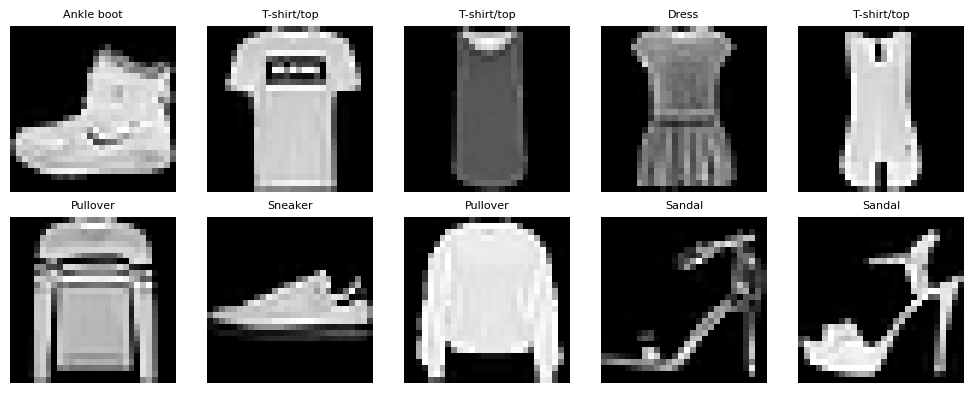

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, idx in zip(axes.flat, range(10)):
    im, lb = train_ds[idx]
    # Denormalizacja wyłącznie na potrzeby poprawnego wyświetlenia obrazu
    ax.imshow(im.squeeze() * std + mean, cmap="gray")
    ax.set_title(classes[lb], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 4. Definicja i inicjalizacja modeli

In [4]:
class MLP(nn.Module):
    """
    Perceptron wielowarstwowy pozwalający na dynamiczną definicję liczby i rozmiaru warstw ukrytych.
    """
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        # Wypłaszczenie obrazu 2D do wektora 1D
        layers = [nn.Flatten()]
        current_dim = in_dim

        # Iteracyjne dodawanie warstw ukrytych i funkcji aktywacji ReLU
        for h in hidden:
            layers.append(nn.Linear(current_dim, h))
            layers.append(nn.ReLU())
            current_dim = h

        # Ostatnia warstwa wyjściowa (logity)
        layers.append(nn.Linear(current_dim, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [5]:
# Model 1- jedna warstwa ukryta (128)
torch.manual_seed(0)
model1 = MLP(hidden=(128, )).to(device)
print(model1)
n_params1 = sum(p.numel() for p in model1.parameters())
print("Liczba parametrów:", n_params1)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Liczba parametrów: 101770


In [6]:
# Model2- dwie warstwy ukryte (256,128)
torch.manual_seed(0)
model2 = MLP(hidden=(256,128)).to(device)
print(model2)
n_params2 = sum(p.numel() for p in model2.parameters())
print("Liczba parametrów:", n_params2)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Liczba parametrów: 235146


In [7]:
# Model3- trzy warstwy ukryte (512,256,128)
torch.manual_seed(0)
model3 = MLP(hidden=(512, 256, 128)).to(device)
print(model3)
n_params3 = sum(p.numel() for p in model3.parameters())
print("Liczba parametrów:", n_params3)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Liczba parametrów: 567434


## 5. Funkcje pomocnicze: ewaluacja i trening

In [8]:
def evaluate(model, dl):
    """
    Funkcja obliczająca stratę oraz dokładność (accuracy) modelu na zadanym zbiorze danych.
    """
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0

    # Parametr reduction="sum" pozwala na dokładne uśrednienie straty po całym zbiorze
    crit = nn.CrossEntropyLoss(reduction="sum")

    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            # Zliczanie poprawnych trafień - wyciąganie indeksu z największym logitem
            correct += (out.argmax(dim=1) == yb).sum().item()
            total += yb.numel()

    return loss_sum / total, correct / total

def train_and_validate(model, train_dl, test_dl, epochs=8, lr=1e-3):
    """
    Główna pętla ucząca model z wykorzystaniem optymalizatora Adam i funkcji straty CrossEntropyLoss.
    Zwraca wytrenowany model oraz słownik z historią metryk.
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "test_loss": [], "test_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = 0.0

        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

            run_loss += loss.item() * yb.numel()

        train_loss = run_loss / len(train_dl.dataset)
        test_loss, test_acc = evaluate(model, test_dl)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Epoka {epoch:2d} | Train Loss: {train_loss:.3f} | Test Loss: {test_loss:.3f} | Test Acc: {test_acc*100:.2f}%")

    return model, history

## 6. Trening modeli i zestawienie wyników

In [9]:
trained_model1, history1 = train_and_validate(model1, train_dl, test_dl)

Epoka  1 | Train Loss: 0.491 | Test Loss: 0.441 | Test Acc: 84.22%
Epoka  2 | Train Loss: 0.367 | Test Loss: 0.383 | Test Acc: 85.92%
Epoka  3 | Train Loss: 0.328 | Test Loss: 0.378 | Test Acc: 86.52%
Epoka  4 | Train Loss: 0.305 | Test Loss: 0.349 | Test Acc: 87.45%
Epoka  5 | Train Loss: 0.286 | Test Loss: 0.346 | Test Acc: 87.89%
Epoka  6 | Train Loss: 0.272 | Test Loss: 0.349 | Test Acc: 87.97%
Epoka  7 | Train Loss: 0.256 | Test Loss: 0.346 | Test Acc: 87.68%
Epoka  8 | Train Loss: 0.244 | Test Loss: 0.337 | Test Acc: 88.46%


In [10]:
trained_model2, history2 = train_and_validate(model2, train_dl, test_dl)

Epoka  1 | Train Loss: 0.485 | Test Loss: 0.405 | Test Acc: 85.53%
Epoka  2 | Train Loss: 0.352 | Test Loss: 0.387 | Test Acc: 86.06%
Epoka  3 | Train Loss: 0.311 | Test Loss: 0.356 | Test Acc: 87.04%
Epoka  4 | Train Loss: 0.286 | Test Loss: 0.345 | Test Acc: 87.57%
Epoka  5 | Train Loss: 0.267 | Test Loss: 0.338 | Test Acc: 87.81%
Epoka  6 | Train Loss: 0.250 | Test Loss: 0.325 | Test Acc: 88.63%
Epoka  7 | Train Loss: 0.237 | Test Loss: 0.329 | Test Acc: 88.60%
Epoka  8 | Train Loss: 0.221 | Test Loss: 0.329 | Test Acc: 88.71%


In [11]:
trained_model3, history3 = train_and_validate(model3, train_dl, test_dl)

Epoka  1 | Train Loss: 0.486 | Test Loss: 0.408 | Test Acc: 84.58%
Epoka  2 | Train Loss: 0.351 | Test Loss: 0.375 | Test Acc: 86.47%
Epoka  3 | Train Loss: 0.312 | Test Loss: 0.355 | Test Acc: 87.04%
Epoka  4 | Train Loss: 0.285 | Test Loss: 0.348 | Test Acc: 87.54%
Epoka  5 | Train Loss: 0.265 | Test Loss: 0.333 | Test Acc: 88.02%
Epoka  6 | Train Loss: 0.247 | Test Loss: 0.344 | Test Acc: 87.95%
Epoka  7 | Train Loss: 0.233 | Test Loss: 0.334 | Test Acc: 88.60%
Epoka  8 | Train Loss: 0.223 | Test Loss: 0.328 | Test Acc: 88.77%


In [12]:
# Wyciągnięcie ostatecznego wyniku z ostatniej epoki
acc1 = history1["test_acc"][-1] * 100
acc2 = history2["test_acc"][-1] * 100
acc3 = history3["test_acc"][-1] * 100

results_df = pd.DataFrame({
    "Wariant modelu": ["Model 1", "Model 2", "Model 3"],
    "Architektura (warstwy ukryte)": ["(128,)", "(256, 128)", "(512, 256, 128)"],
    "Liczba parametrów": [n_params1, n_params2, n_params3],
    "Accuracy (ostatnia epoka)": [f"{acc1:.2f}%", f"{acc2:.2f}%", f"{acc3:.2f}%"]
})

display(results_df)

,Wariant modelu,Architektura (warstwy ukryte),Liczba parametrów,Accuracy (ostatnia epoka)
0,Model 1,"(128,)",101770,88.46%
1,Model 2,"(256, 128)",235146,88.71%
2,Model 3,"(512, 256, 128)",567434,88.77%


## 7. Krzywa uczenia dla najlepszego wariantu

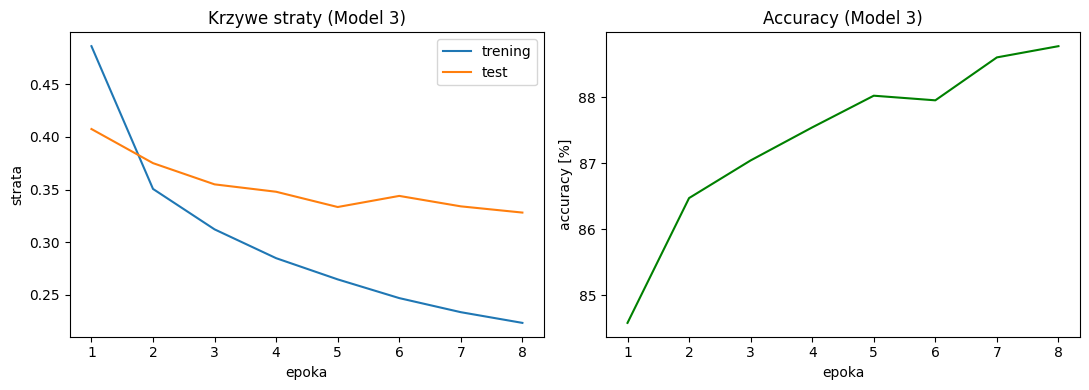

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

epoki = range(1, len(history3["train_loss"]) + 1)

ax1.plot(epoki, history3["train_loss"], label="trening")
ax1.plot(epoki, history3["test_loss"], label="test")
ax1.set_xlabel("epoka")
ax1.set_ylabel("strata")
ax1.legend()
ax1.set_title("Krzywe straty (Model 3)")

ax2.plot(epoki, [a * 100 for a in history3["test_acc"]], color="green")
ax2.set_xlabel("epoka")
ax2.set_ylabel("accuracy [%]")
ax2.set_title("Accuracy (Model 3)")

plt.tight_layout()
plt.show()

## 8. Wizualizacja poprawnych i błędnych predykcji

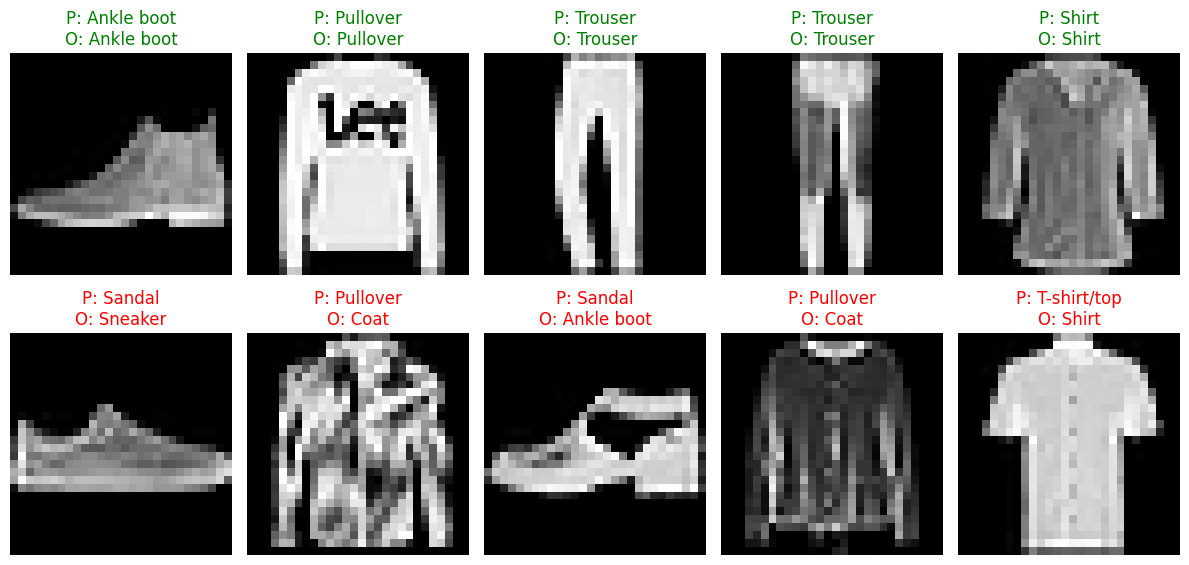

In [14]:
# Pobranie jednej paczki danych testowych
xb, yb = next(iter(test_dl))

# Przejście w tryb ewaluacji i obliczenie predykcji, a następnie przeniesienie wyniku na CPU do wizualizacji
trained_model3.eval()
with torch.no_grad():
    out = trained_model3(xb.to(device))
    preds = out.argmax(dim=1).cpu()

# Wyszukanie indeksów poprawnych (ok) i błędnych (err) predykcji
ok_idx = torch.where(preds == yb)[0][:5]
err_idx = torch.where(preds != yb)[0][:5]
indices = torch.cat([ok_idx, err_idx])

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for ax, i in zip(axes.flat, indices):
    color = "green" if preds[i] == yb[i] else "red"
    # Denormalizacja obrazu do poprawnego wyświetlenia
    ax.imshow(xb[i].squeeze() * std + mean, cmap="gray")
    ax.set_title(f"P: {classes[preds[i]]}\nO: {classes[yb[i]]}", color=color)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 10. Macierz pomyłek

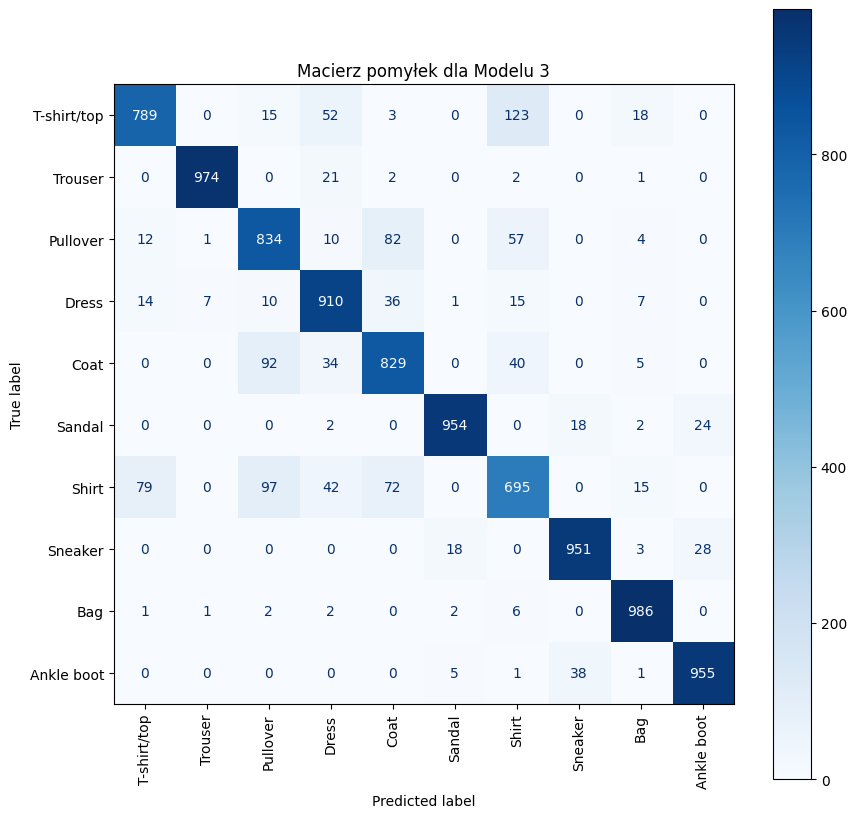

In [15]:
all_preds = []
all_labels = []

trained_model3.eval()
with torch.no_grad():
    for xb, yb in test_dl:
        out = trained_model3(xb.to(device))
        preds = out.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(yb.numpy())

# Generowanie i wizualizacja macierzy pomyłek z użyciem Scikit-Learn
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation="vertical")
plt.title("Macierz pomyłek dla Modelu 3")
plt.show()